# 07b · Player-level view: do Combine drills predict a DL's average get-off?
**DS 5110 Big Data Systems — Final Project: Trench Play (OL and DL)**

**Team contribution.** The question and the first scatter (10-yard split against average get-off) are **Isaac Marr's** (EDA). The correlations, the median imputation and the Spark ML linear regression are **Jarmarr Washington's**. This notebook keeps their steps as they wrote them and then adds what the rest of the project needs:
* the **tracking traits** from notebook 03 next to the stopwatch drills (does tracking add anything at the player level?);
* **repeated cross-validation** instead of one 43 / 12 split, so the R² comes with an uncertainty band;
* an **out-of-time test** on the 2025 draft class, as in notebooks 05–07;
* a **reconciliation** with the snap-level models of notebook 07, which found much smaller effects.

**Why look at players, not snaps.** Notebooks 05–07 predict every snap. Averaging a player's snaps removes snap-to-snap noise (the down, the blocker, the stunt), so a player-level model asks a cleaner question: *do players who test faster get off the ball faster on average?*

**Population (as in the original analysis).** DL rookies, NFL regular + post season, snaps lined up on the edge or the interior with a recorded get-off; players with 100+ such snaps and a recorded 10-yard split.

**Inputs:** `processed/line_player_play.parquet`, `line_players.parquet` (stopwatch drills), `trait_indices.parquet` (tracking traits); `outputs/tables/07_*.csv` (optional, for the reconciliation).
**Outputs:** `outputs/tables/07b_*.csv`, `outputs/figures/07b_*.png`.

In [1]:
import sys, os
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
import config as C

spark = C.get_spark("07b_player_level")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, AQUA, GREY = "#2a6fdb", "#e07b39", "#00b894", "#8a8a8a"
CV_REPEATS = int(os.environ.get("PLAYER_CV_REPEATS", "20"))
STOPWATCH = ["ten_yd_split", "forty", "three_cone", "short_shuttle", "vertical", "broad_jump"]
TRACKING = ["trk_first_step", "trk_lateral", "trk_burst"]
LABELS = {"ten_yd_split": "10-yard split (s)", "forty": "40-yard dash (s)", "three_cone": "3-cone (s)", "short_shuttle": "short shuttle (s)",
          "vertical": "vertical jump (in)", "broad_jump": "broad jump (in)", "trk_first_step": "tracking: first step (index)",
          "trk_lateral": "tracking: lateral agility (index)", "trk_burst": "tracking: burst (index)", "edge_share": "share of edge snaps"}

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44357 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up _JAVA_OPTIONS: -XX:+UnlockDiagnosticVMOptions -XX:DisableIntrinsic=_base64_encodeBlock,_base64_decodeBlock
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.ne

26/11/26 19:44:37 WARN Utils: Your hostname, vm resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/26 19:44:37 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/26 19:44:37 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. One row per DL: average get-off, rush snaps, share of edge snaps (Spark)

In [2]:
plays = spark.read.parquet(C.p("line_player_play.parquet"))
players = spark.read.parquet(C.p("line_players.parquet"))
traits = spark.read.parquet(C.p("trait_indices.parquet")).select("nfl_id", *TRACKING)
rush = plays.filter((F.col("line_group") == "DL") & F.col("season_type").isin("REG", "POST") & F.col("player_get_off").isNotNull()
                    & F.col("lined_up_position").isin("EDGE", "INTERIOR_LINE"))
per_player = (rush.groupBy("nfl_id").agg(F.count("*").alias("rush_snaps"), F.avg("player_get_off").alias("mean_get_off"),
                                         F.avg((F.col("lined_up_position") == "EDGE").cast("double")).alias("edge_share"))
                  .join(players.select("nfl_id", "display_name", "draft_year", *STOPWATCH), "nfl_id")
                  .join(traits, "nfl_id", "left"))
dl = per_player.filter((F.col("rush_snaps") >= 100) & F.col("ten_yd_split").isNotNull()).toPandas().sort_values("nfl_id")
print(f"{len(dl)} DL with 100+ rush snaps and a 10-yard split (draft classes: {dl.draft_year.value_counts().sort_index().to_dict()})")
print("missing drills:", dl[STOPWATCH + TRACKING].isna().sum().to_dict())
dl[["nfl_id", "rush_snaps", "mean_get_off", "edge_share"] + STOPWATCH + TRACKING].describe().round(3).T

55 DL with 100+ rush snaps and a 10-yard split (draft classes: {2023: 22, 2024: 22, 2025: 11})
missing drills: {'ten_yd_split': 0, 'forty': 0, 'three_cone': 31, 'short_shuttle': 32, 'vertical': 2, 'broad_jump': 4, 'trk_first_step': 0, 'trk_lateral': 3, 'trk_burst': 0}


,count,mean,std,min,25%,50%,75%,max
nfl_id,55.0,56991.091,870.502,55867.000,56032.000,57156.000,57338.000,58458.000
rush_snaps,55.0,478.327,422.196,104.000,176.500,285.000,708.000,1802.000
mean_get_off,55.0,1.035,0.096,0.845,0.959,1.034,1.110,1.206
edge_share,55.0,0.501,0.428,0.000,0.059,0.286,0.955,1.000
ten_yd_split,55.0,1.687,0.077,1.540,1.635,1.670,1.735,1.880
forty,55.0,4.829,0.246,4.430,4.645,4.810,4.970,5.410
three_cone,24.0,7.432,0.261,7.020,7.280,7.385,7.600,8.010
short_shuttle,23.0,4.552,0.210,4.180,4.390,4.540,4.705,5.030
vertical,53.0,32.443,3.577,23.000,30.000,32.500,35.000,38.000
broad_jump,51.0,116.176,8.037,96.000,111.000,116.000,121.500,132.000


## 2. Correlations with average get-off (Jarmarr's table, plus the tracking traits)
Get-off is a time, so a **positive** r for a timed drill (10-yard split, 40, 3-cone, shuttle) and a **negative** r for a jump or a tracking index (higher = better) both mean "better tester, faster get-off". The 95% interval uses the Fisher z transform.

In [3]:
def corr_row(x, name):
    d = dl[[name, "mean_get_off"]].dropna()
    n = len(d); r = d[name].corr(d.mean_get_off); rho = d[name].corr(d.mean_get_off, method="spearman")
    z, se = np.arctanh(r), 1 / np.sqrt(max(n - 3, 1))
    return dict(feature=name, label=LABELS[name], kind=x, n=n, pearson_r=r, ci_lo=np.tanh(z - 1.96 * se), ci_hi=np.tanh(z + 1.96 * se),
                spearman_rho=rho)
corr = pd.DataFrame([corr_row("stopwatch", c) for c in STOPWATCH] + [corr_row("tracking", c) for c in TRACKING]
                    + [corr_row("context", "edge_share")])
corr.to_csv(C.TABLE_DIR / "07b_correlations.csv", index=False)
corr.round(3)

,feature,label,kind,n,pearson_r,ci_lo,ci_hi,spearman_rho
0,ten_yd_split,10-yard split (s),stopwatch,55,0.694,0.526,0.810,0.677
1,forty,40-yard dash (s),stopwatch,55,0.698,0.531,0.813,0.710
2,three_cone,3-cone (s),stopwatch,24,0.605,0.267,0.811,0.563
3,short_shuttle,short shuttle (s),stopwatch,23,0.532,0.154,0.775,0.483
4,vertical,vertical jump (in),stopwatch,53,-0.600,-0.749,-0.393,-0.593
5,broad_jump,broad jump (in),stopwatch,51,-0.690,-0.811,-0.512,-0.663
6,trk_first_step,tracking: first step (index),tracking,55,-0.120,-0.373,0.150,-0.142
7,trk_lateral,tracking: lateral agility (index),tracking,52,-0.354,-0.571,-0.089,-0.272
8,trk_burst,tracking: burst (index),tracking,55,-0.341,-0.556,-0.084,-0.346
9,edge_share,share of edge snaps,context,55,-0.613,-0.755,-0.415,-0.655


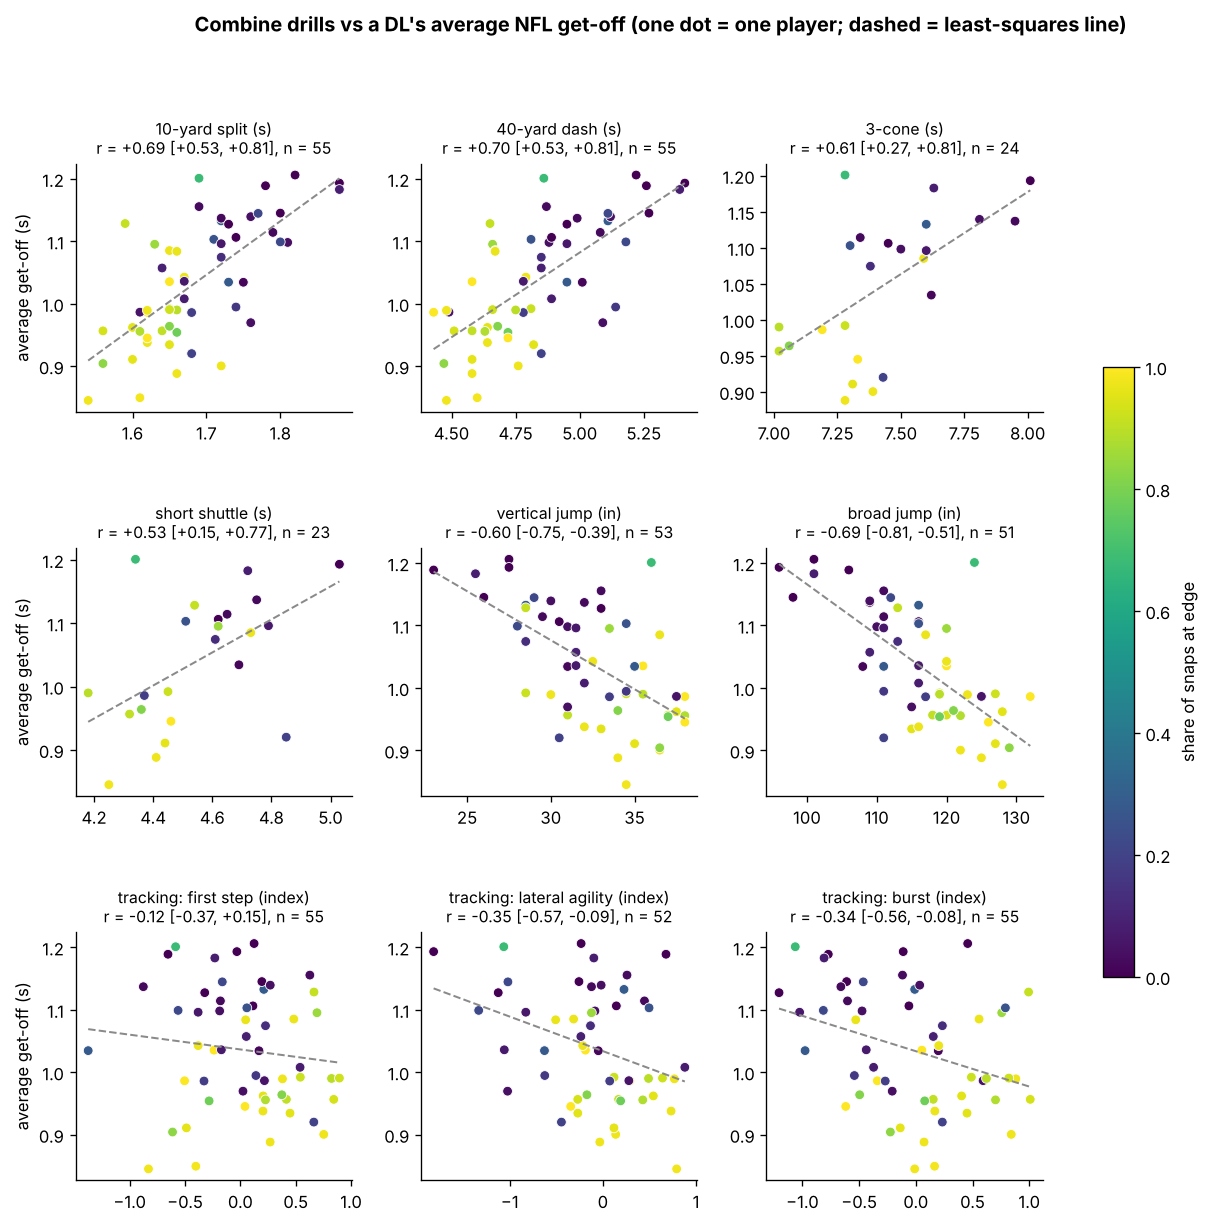

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for ax, name in zip(axes.flat, STOPWATCH + TRACKING):
    d = dl[[name, "mean_get_off", "edge_share"]].dropna()
    sc = ax.scatter(d[name], d.mean_get_off, c=d.edge_share, cmap="viridis", vmin=0, vmax=1, s=34, edgecolors="white", linewidths=.5)
    b = np.polyfit(d[name], d.mean_get_off, 1); xs = np.linspace(d[name].min(), d[name].max(), 20)
    ax.plot(xs, np.polyval(b, xs), color=GREY, lw=1.2, ls="--")
    rr = corr.set_index("feature").loc[name]
    ax.set_title(f"{LABELS[name]}\nr = {rr.pearson_r:+.2f} [{rr.ci_lo:+.2f}, {rr.ci_hi:+.2f}], n = {int(rr.n)}", fontsize=9.5)
    ax.set_ylabel("average get-off (s)" if ax in axes[:, 0] else "")
fig.subplots_adjust(hspace=.55, wspace=.25)
fig.colorbar(sc, ax=axes, shrink=.6, label="share of snaps at edge")
fig.suptitle("Combine drills vs a DL's average NFL get-off (one dot = one player; dashed = least-squares line)", fontweight="bold", y=0.995)
fig.savefig(C.FIG_DIR / "07b_drills_vs_mean_getoff.png", bbox_inches="tight"); plt.show()

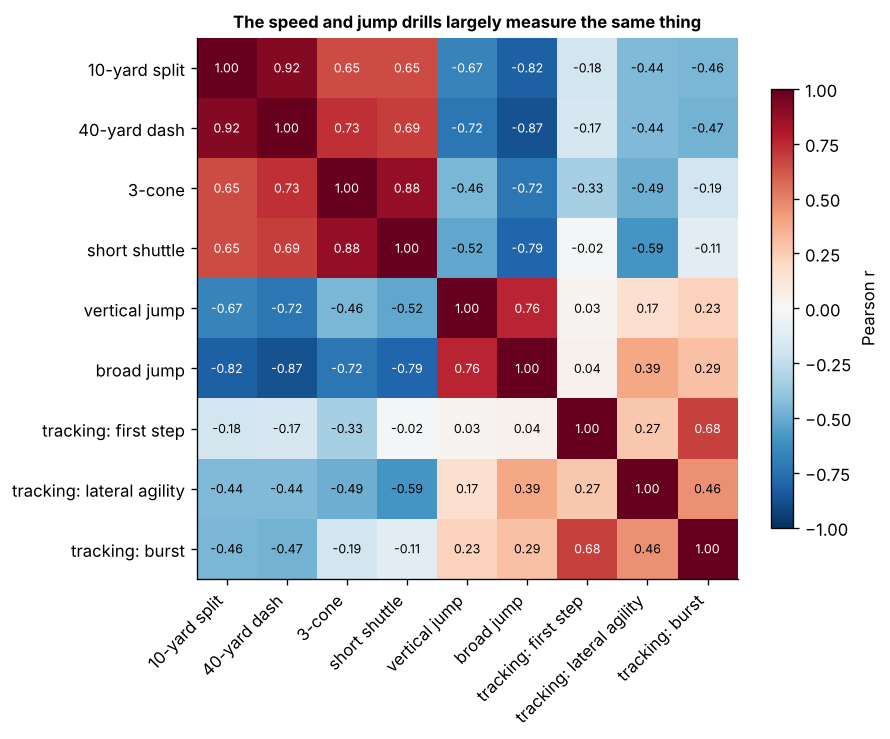

In [5]:
# how much the drills overlap with each other (Jarmarr's inter-correlation table)
inter = dl[STOPWATCH + TRACKING].corr().round(2)
inter.to_csv(C.TABLE_DIR / "07b_drill_intercorrelations.csv")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(inter.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(inter)), [LABELS[c].split(" (")[0] for c in inter.columns], rotation=45, ha="right")
ax.set_yticks(range(len(inter)), [LABELS[c].split(" (")[0] for c in inter.index])
for i in range(len(inter)):
    for j in range(len(inter)):
        ax.text(j, i, f"{inter.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(inter.values[i, j]) > .6 else "black")
fig.colorbar(im, ax=ax, shrink=.8, label="Pearson r")
ax.set_title("The speed and jump drills largely measure the same thing", fontweight="bold", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "07b_drill_intercorrelations.png", bbox_inches="tight"); plt.show()

## 3. Jarmarr's model, as written
80 / 20 random split of players (seed 42), a mean baseline, median imputation of the drills many players skipped (fitted on the training players only), and a Spark ML linear regression on the six stopwatch drills plus the share of edge snaps.

In [6]:
MISSING = ["three_cone", "short_shuttle", "vertical", "broad_jump"]
JW_FEATURES = ["ten_yd_split", "forty"] + [f"{c}_imputed" for c in MISSING] + ["edge_share"]
dl_spark = spark.createDataFrame(dl[["nfl_id", "draft_year", "mean_get_off", "edge_share"] + STOPWATCH + TRACKING].astype(
    {c: float for c in STOPWATCH + TRACKING + ["edge_share", "mean_get_off"]}))
train, test = dl_spark.randomSplit([0.8, 0.2], seed=42)
print("training players:", train.count(), "| test players:", test.count())

baseline = train.agg(F.avg("mean_get_off")).first()[0]
base_pred = test.withColumn("prediction", F.lit(baseline))
jw_pipe = Pipeline(stages=[Imputer(inputCols=MISSING, outputCols=[f"{c}_imputed" for c in MISSING], strategy="median"),
                           VectorAssembler(inputCols=JW_FEATURES, outputCol="features"),
                           LinearRegression(featuresCol="features", labelCol="mean_get_off", regParam=0.0)])
jw_model = jw_pipe.fit(train)
jw_pred = jw_model.transform(test)
ev = lambda m, df: RegressionEvaluator(labelCol="mean_get_off", predictionCol="prediction", metricName=m).evaluate(df)
jw_results = pd.DataFrame([{"model": name, **{m.upper(): ev(m, df) for m in ["mae", "rmse", "r2"]}}
                           for name, df in [("baseline: training mean", base_pred), ("linear regression (stopwatch + edge share)", jw_pred)]])
lr_stage = jw_model.stages[-1]
coefs = pd.DataFrame({"feature": JW_FEATURES, "coefficient": lr_stage.coefficients.toArray()})
print("intercept", round(lr_stage.intercept, 4)); display(coefs.round(4))
jw_results.round(4)

training players: 43 | test players: 12


intercept 0.0343


,feature,coefficient
0,ten_yd_split,0.4003
1,forty,0.0689
2,three_cone_imputed,0.1045
3,short_shuttle_imputed,-0.1076
4,vertical_imputed,-0.0060
5,broad_jump_imputed,-0.0009
6,edge_share,-0.0058


,model,MAE,RMSE,R2
0,baseline: training mean,0.0734,0.0822,-0.1342
1,linear regression (stopwatch + edge share),0.0518,0.0636,0.3218


## 4. How stable is that R²? Repeated cross-validation
With 12 test players, one split can move R² a lot. Here every player is predicted exactly once per repeat (5 folds), and the split is redrawn `PLAYER_CV_REPEATS` times. Four feature sets are compared, all as Spark ML Pipelines (imputer → assembler → scaler → linear regression; a small ridge penalty keeps the fits stable):
* **edge share only** (context baseline);
* **stopwatch** (Jarmarr's seven features);
* **tracking** traits + edge share;
* **stopwatch + tracking** + edge share.

In [7]:
SETS = {"edge share only": ["edge_share"],
        "stopwatch + edge share": STOPWATCH + ["edge_share"],
        "tracking + edge share": TRACKING + ["edge_share"],
        "stopwatch + tracking + edge share": STOPWATCH + TRACKING + ["edge_share"]}
def make_pipe(cols):
    imp = [c for c in cols if dl[c].isna().any()]
    stages = [Imputer(inputCols=imp, outputCols=[f"{c}_i" for c in imp], strategy="median")] if imp else []
    feats = [f"{c}_i" if c in imp else c for c in cols]
    return Pipeline(stages=stages + [VectorAssembler(inputCols=feats, outputCol="raw"),
                                     StandardScaler(inputCol="raw", outputCol="features", withMean=True, withStd=True),
                                     LinearRegression(featuresCol="features", labelCol="mean_get_off", regParam=0.01)])
def oof_r2(df_pd, pipe, folds):
    """Out-of-fold predictions for every player, then one R² over all of them."""
    sdf = spark.createDataFrame(df_pd.assign(fold=folds)).cache()
    preds = []
    for k in sorted(set(folds)):
        m = pipe.fit(sdf.filter(F.col("fold") != k))
        preds.append(m.transform(sdf.filter(F.col("fold") == k)).select("nfl_id", "mean_get_off", "prediction").toPandas())
    sdf.unpersist()
    p = pd.concat(preds)
    return 1 - ((p.mean_get_off - p.prediction) ** 2).sum() / ((p.mean_get_off - p.mean_get_off.mean()) ** 2).sum()

base_cols = ["nfl_id", "draft_year", "mean_get_off"] + STOPWATCH + TRACKING + ["edge_share"]
dd = dl[base_cols].astype({c: float for c in base_cols if c not in ("nfl_id", "draft_year")})
rng = np.random.default_rng(C.SEED)
cv_rows = []
for rep in range(CV_REPEATS):
    folds = rng.permutation(np.arange(len(dd)) % 5)
    for name, cols in SETS.items():
        cv_rows.append(dict(repeat=rep, feature_set=name, r2=oof_r2(dd, make_pipe(cols), folds)))
cv = pd.DataFrame(cv_rows)
cv_summary = (cv.groupby("feature_set").r2.agg(mean="mean", p2_5=lambda s: s.quantile(.025), p97_5=lambda s: s.quantile(.975))
                .reindex(SETS.keys()).reset_index())
cv.to_csv(C.TABLE_DIR / "07b_repeated_cv.csv", index=False); cv_summary.to_csv(C.TABLE_DIR / "07b_repeated_cv_summary.csv", index=False)
cv_summary.round(3)

,feature_set,mean,p2_5,p97_5
0,edge share only,0.329,0.288,0.353
1,stopwatch + edge share,0.414,0.351,0.457
2,tracking + edge share,0.278,0.187,0.340
3,stopwatch + tracking + edge share,0.351,0.259,0.419


## 5. Out-of-time test: train on the 2023–24 classes, predict the 2025 class
The same rule as the snap-level models (notebook 05): players from the newest class are never seen in training.

In [8]:
tr_pd, te_pd = dd[dd.draft_year < C.TEST_DRAFT_CLASS], dd[dd.draft_year == C.TEST_DRAFT_CLASS]
oot = []
if len(te_pd) >= 5:
    tr_s, te_s = spark.createDataFrame(tr_pd), spark.createDataFrame(te_pd)
    for name, cols in SETS.items():
        p = make_pipe(cols).fit(tr_s).transform(te_s).select("mean_get_off", "prediction").toPandas()
        r2 = 1 - ((p.mean_get_off - p.prediction) ** 2).sum() / ((p.mean_get_off - p.mean_get_off.mean()) ** 2).sum()
        oot.append(dict(feature_set=name, train_players=len(tr_pd), test_players=len(te_pd), test_r2=r2,
                        test_mae=float(np.abs(p.mean_get_off - p.prediction).mean())))
oot = pd.DataFrame(oot)
oot.to_csv(C.TABLE_DIR / "07b_out_of_time_2025.csv", index=False)
oot.round(3) if len(oot) else print("fewer than 5 players from the 2025 class: out-of-time test skipped")

,feature_set,train_players,test_players,test_r2,test_mae
0,edge share only,44,11,-0.110,0.074
1,stopwatch + edge share,44,11,0.051,0.058
2,tracking + edge share,44,11,-0.136,0.076
3,stopwatch + tracking + edge share,44,11,-0.246,0.070


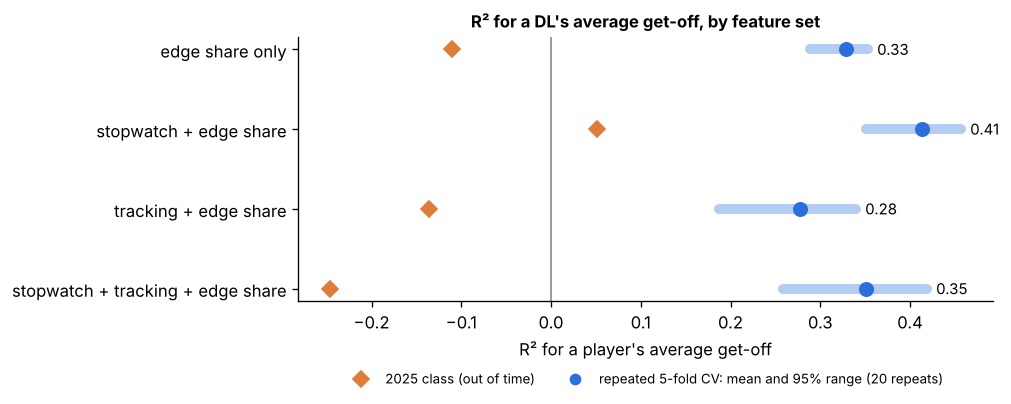

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
order = list(SETS.keys())
for i, name in enumerate(order):
    v = cv[cv.feature_set == name].r2
    ax.plot([v.quantile(.025), v.quantile(.975)], [i, i], color=BLUE, lw=6, alpha=.35, solid_capstyle="round")
    ax.plot(v.mean(), i, "o", color=BLUE, ms=8)
    ax.text(v.quantile(.975) + .01, i, f"{v.mean():.2f}", va="center", fontsize=9)
    if len(oot):
        ax.plot(oot.set_index("feature_set").loc[name, "test_r2"], i, "D", color=ORANGE, ms=7,
                label="2025 class (out of time)" if i == 0 else None)
ax.axvline(0, color=GREY, lw=1)
ax.plot([], [], "o", color=BLUE, label=f"repeated 5-fold CV: mean and 95% range ({CV_REPEATS} repeats)")
ax.set_yticks(range(len(order)), order); ax.invert_yaxis(); ax.set_xlabel("R² for a player's average get-off")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
ax.set_title("R² for a DL's average get-off, by feature set", fontweight="bold", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "07b_player_level_r2.png", bbox_inches="tight"); plt.show()

## 6. Reconciling the player view with the snap-level models
Notebook 07 found that adding a trait to the snap-level model raised get-off R² by only about 0.006. The two results agree once you split the variance of get-off into a **between-player** part (who the player is) and a **within-player** part (snap-to-snap). A player-level R² only applies to the between-player part, so its snap-level equivalent is roughly

**snap-level gain ≈ player-level R² × between-player share of variance.**

In [10]:
agg = (rush.groupBy("nfl_id").agg(F.count("*").alias("n"), F.avg("player_get_off").alias("m"),
                                  F.sum(F.col("player_get_off") ** 2).alias("ss")).toPandas())
N, k = agg.n.sum(), len(agg)
grand = (agg.n * agg.m).sum() / N
ssb = (agg.n * (agg.m - grand) ** 2).sum()
ssw = (agg.ss - agg.n * agg.m ** 2).sum()
msb, msw = ssb / (k - 1), ssw / (N - k)
n0 = (N - (agg.n ** 2).sum() / N) / (k - 1)
var_b = max((msb - msw) / n0, 0)
between_share = var_b / (var_b + msw)
best = cv_summary.set_index("feature_set")
rec = [dict(quantity="between-player share of get-off variance (ICC, all DL rush snaps)", value=between_share)]
for name in ["stopwatch + edge share", "tracking + edge share", "stopwatch + tracking + edge share"]:
    rec.append(dict(quantity=f"implied snap-level gain from player-level R², {name}",
                    value=max(best.loc[name, "mean"] - best.loc["edge share only", "mean"], 0) * between_share))
te = C.TABLE_DIR / "07_trait_effects.csv"
if te.exists():
    t = pd.read_csv(te).query("task == 'dl_getoff'").set_index("model")
    for m in ["burst", "stopwatch", "traits"]:
        if m in t.index:
            rec.append(dict(quantity=f"measured snap-level gain in notebook 07 ({m})", value=t.loc[m, "delta"]))
recon = pd.DataFrame(rec)
recon.to_csv(C.TABLE_DIR / "07b_reconciliation.csv", index=False)
recon.round(4)

,quantity,value
0,"between-player share of get-off variance (ICC,...",0.0977
1,"implied snap-level gain from player-level R², ...",0.0082
2,"implied snap-level gain from player-level R², ...",0.0000
3,"implied snap-level gain from player-level R², ...",0.0021
4,measured snap-level gain in notebook 07 (burst),0.0063
5,measured snap-level gain in notebook 07 (stopw...,0.0039
6,measured snap-level gain in notebook 07 (traits),0.0091


**Reading it.** Only a small share of the variation in get-off is between players. Most of it comes from the snap itself: the down, the call, the blocker. So even a player-level model that explains a real part of the between-player differences can only add a few thousandths of R² when it is scored snap by snap. That is the size notebook 07 measured. The player view and the snap view tell one story: **within the 2023–25 classes, the stopwatch speed drills help separate faster and slower get-off players beyond alignment alone, but get-off on any one snap is mostly the snap itself.** The out-of-time check has only about a dozen players from the 2025 class, too few to confirm or rule out the player-level gain, so the report should quote the cross-validated range together with that caveat.

In [11]:
summary = pd.concat([corr.assign(section="correlation")[["section", "feature", "n", "pearson_r", "ci_lo", "ci_hi"]],
                     cv_summary.assign(section="repeated CV R²").rename(columns={"feature_set": "feature", "mean": "pearson_r",
                                                                                 "p2_5": "ci_lo", "p97_5": "ci_hi"})], ignore_index=True)
summary.to_csv(C.TABLE_DIR / "07b_player_level_summary.csv", index=False)
spark.stop()